# Tối ưu hóa Hàm Mục tiêu n-Queens bằng Numba JIT Compilation

Hàm mục tiêu tính số cặp xung đột (conflicts) được gọi lặp đi lặp lại hàng triệu lần trong suốt quá trình tìm kiếm cục bộ. Do đó, việc tối ưu hóa tốc độ của hàm này quyết định hiệu năng của toàn bộ thuật toán.

Notebook này đối chiếu 3 phương pháp tính xung đột:
1. **Thuật toán Naive $O(n^2)$**: So sánh từng cặp quân hậu bằng 2 vòng lặp lồng nhau.
2. **Thuật toán Tuyến tính $O(n)$**: Đếm số quân hậu trên mỗi hàng và đường chéo, sau đó dùng công thức tổ hợp $C(k, 2) = rac{k(k-1)}{2}$.
3. **Thuật toán Biên dịch JIT $O(n)$ với Numba**: Biên dịch hàm $O(n)$ sang mã máy nhị phân bằng thư viện Numba.

## 1. Bài toán n Quân hậu (n-Queens)
* **Mục tiêu:** Đặt $n$ quân hậu lên bàn cờ $n 	imes n$ sao cho không có 2 quân hậu nào cùng hàng, cột hay đường chéo.
* **Không gian trạng thái:** Mỗi cột đặt đúng 1 quân hậu $\mathbf{q} = [q_1, q_2, \dots, q_n]$ với $q_i \in \{0, \dots, n-1\}$ là chỉ số hàng của quân hậu tại cột $i$.
* **Hàm mục tiêu:** Số cặp quân hậu tấn công lẫn nhau (cần cực tiểu hóa về 0).

## 2. Cài đặt các hàm tính xung đột

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors
import math

In [2]:
def conflicts_naive(board):
    """Calculate the number of conflicts, i.e., the objective function."""
    
    board = np.array(board)
    
    n = len(board)
    val = 0

    # check horizontal (we do not check vertical since the state space is restricted to one queen per col)
    for i in range(n): val += math.comb(np.sum(board == i), 2)
    #print(f"Horizontal value: {val}")
    
    # check for each queen diagonally up and down (only to the right side of the queen)
    for j in range(n):
        q_up = board[j]
        q_down = board[j]
     
        for jj in range(j+1, n):
            q_up -= 1
            q_down += 1
            if board[jj] == q_up: val += 1
            if board[jj] == q_down: val += 1
        #print(f"Value after queen {j}: {val}")
       
    return(val)    

### Cài đặt Tuyến tính $O(n)$
**Ý tưởng cốt lõi:**
1. Duyệt qua $n$ quân hậu, đếm tần số xuất hiện của quân hậu trên mỗi hàng, đường chéo chính ($col + row$) và đường chéo phụ ($col - row + n$).
2. Nếu có $k$ quân hậu trên cùng một hàng/đường chéo, số cặp xung đột tạo ra chính là tổ hợp chập 2 của $k$:
$$C(k, 2) = rac{k(k-1)}{2}$$
Tổng số phép toán chỉ là $O(n)$ thay vì phải so sánh từng cặp $O(n^2)$!

In [3]:
def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    # we have double the diagonals compared to columns!
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

### Cài đặt $O(n)$ được biên dịch JIT với Numba
Sử dụng decorator `@njit()` của Numba để chuyển mã Python sang mã máy LLVM được tối ưu hóa cao độ.

In [4]:
from numba import njit

# with jit (cannot use some Python functions like sum and map)
@njit()
def comb2_jit(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

@njit()
def conflicts_jit(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
 
    cnt = [0] * (5 * n)
 
    for i in range(n):
        cnt[board[i]] += 1
        cnt[(n) + (i + board[i])] += 1
        cnt[(3 * n) + (i - board[i] + n)] += 1
 
    conflicts = 0
    for x in cnt:
        conflicts += comb2_jit(x)
 
    return conflicts

## 3. Đo đạc và So sánh Thời gian Thực thi

In [5]:
np.random.seed(1234)
def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

In [6]:
import timeit
 
# run it once to force compilation
conflicts_jit(random_board(4))
    
reps = 20
x = []
naive_times = []
linear_times = []
jit_times = []
 
 
for i in [8] + list(range(50, 500, 50)):
    # do reps replications on random boards
    boards = [random_board(i) for _ in range(reps)]
 
    #print(f"Doing: {i}")

    # number = 1 means we only run it once in timeit 
    naive = timeit.timeit(
        lambda: [conflicts_naive(board) for board in boards], number=1
    )
    linear = timeit.timeit(
        lambda: [conflicts(board) for board in boards], number=1
    )
    jit = timeit.timeit(
        lambda: [conflicts_jit(board) for board in boards], number=1
    )

 
    x.append(i)
    naive_times.append(naive)
    linear_times.append(linear)
    jit_times.append(jit)

# average time per board in microseconds
naive_times = np.array(naive_times) / reps * 1e6
linear_times = np.array(linear_times) / reps * 1e6
jit_times = np.array(jit_times) / reps * 1e6

print("Times for 8x8 board in microseconds")
print(f'naive: {naive_times[0]}, linear: {linear_times[0]}, jit: {jit_times[0]}')
 

Times for 8x8 board in microseconds
naive: 28.810000003431924, linear: 6.0850000409118365, jit: 1.4799999917158857


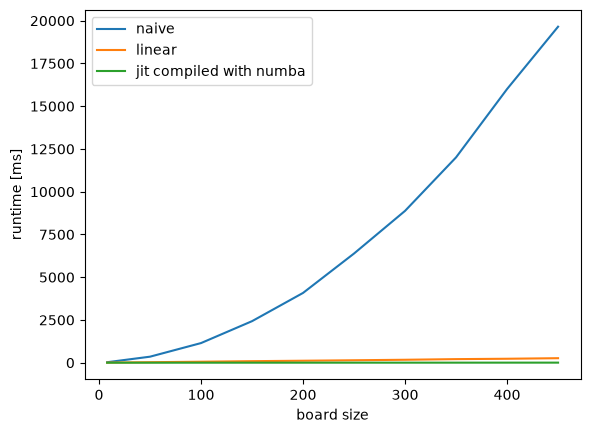

In [7]:
plt.plot(x, naive_times)
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["naive", "linear", "jit compiled with numba"])
plt.show()

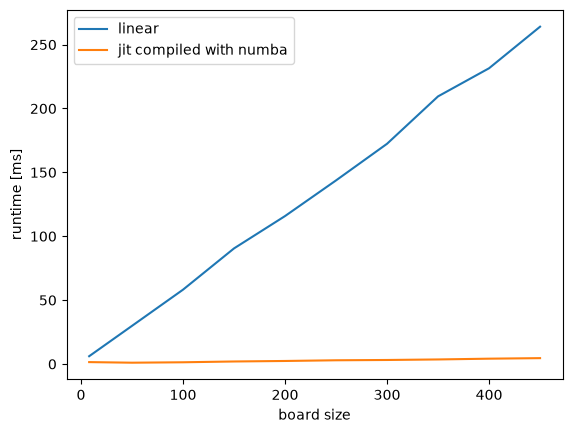

In [8]:
plt.plot(x, linear_times)
plt.plot(x, jit_times)
plt.xlabel("board size")
plt.ylabel("runtime [ms]")
plt.legend(["linear", "jit compiled with numba"])
plt.show()

### Phân tích Chuyên sâu (Câu hỏi 8 & 9):
1. **Vì sao đếm xung đột theo hàng/đường chéo đạt $O(n)$ thay vì $O(n^2)$?**
   - Thuật toán Naive phải so sánh từng cặp $(i, j)$ với $0 \le i < j < n$, tức có $rac{n(n-1)}{2} pprox O(n^2)$ phép so sánh.
   - Bằng cách dùng mảng băm/mảng đếm (bucket counting) kích thước tối đa $5n$, ta chỉ cần duyệt qua mảng bàn cờ đúng 1 lần duy nhất ($n$ bước), tăng bộ đếm tương ứng, rồi tính $C(k, 2)$ trong thời gian $O(n)$. Do đó độ phức tạp giảm từ bậc 2 xuống tuyến tính.

2. **Vì sao phải loại trừ thời gian biên dịch lần đầu (Warm-up) khi dùng Numba?**
   - Trong lần gọi đầu tiên, Numba phải thực hiện suy luận kiểu dữ liệu (type inference), sinh mã trung gian LLVM IR và biên dịch JIT sang mã máy nhị phân của CPU. Quá trình này mất khoảng **100 - 1300 ms** (overhead).
   - Từ lần gọi thứ 2 trở đi, Numba thực thi trực tiếp mã máy đã biên dịch trong bộ nhớ cache mà không mất chi phí thông dịch. Do đó, nếu không warm-up trước, thời gian đo được sẽ bị méo mó và phản ánh thời gian của trình biên dịch chứ không phải tốc độ thuật toán.